# 03 — Preprocessing and baselines

This notebook turns the labelled service-request file into a leakage-safe training matrix and fits two baselines. It does not tune a champion model.

Predictors are limited to fields that can be known when a request is logged. Completed Date, Changed on, resolution duration, and the target are not predictors. The preprocessor is fit on the training period only. Validation and test rows are not resampled.

The split is chronological. Training is 2023–2024, validation is 2025, and the locked test is 1 January 2026 through 30 April 2026. Labelled requests created after 30 April 2026 stay out of all three splits because the class mix breaks in May 2026, while the extract ends on 6 October 2026.


## 1. Setup


In [1]:
from pathlib import Path
import sys
import time
import warnings

import pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.evaluation import classification_scores, metrics_tables, probability_summary, save_metric_tables
from src.preprocessing import (
    MATURE_END,
    MODEL_FEATURES,
    RARE_CATEGORY_MIN_COUNT,
    TRAIN_END,
    VALIDATION_END,
    build_baseline_preprocessor,
    chronological_splits,
    feature_decision_table,
    logging_feature_frame,
    make_logistic_baseline,
    make_most_frequent_baseline,
)
from src.visualization import plot_confusion_matrix

config.set_random_seeds()
print(f"Project root: {config.PROJECT_ROOT}")
print(f"Random seed: {config.RANDOM_SEED}")
print(f"Train through: {TRAIN_END.date()}")
print(f"Validation through: {VALIDATION_END.date()}")
print(f"Locked test through: {MATURE_END.date()}")
print(f"Rare-category minimum (training rows): {RARE_CATEGORY_MIN_COUNT}")


Project root: /workspace
Random seed: 42
Train through: 2024-12-31
Validation through: 2025-12-31
Locked test through: 2026-04-30
Rare-category minimum (training rows): 200


## 2. Fields available at logging

The decision table is the baseline feature policy. A column is included only when the extract supports treating it as known at the moment the request is logged. Work Center is stored on every row, but nothing records when it was assigned. The next section measures, on the training period only, whether the centre is just a copy of the complaint type.


In [2]:
decisions = feature_decision_table()
decision_path = config.TABLES_DIR / "04_feature_decisions.csv"
decisions.to_csv(decision_path, index=False)
print(decision_path)
display(decisions)

source_columns = [
    "Created_On_Date",
    "C3_Complaint_Type",
    "Suburb",
    "Ward",
    "Sub_Council",
    "Work_Center",
    "resolution_outcome",
]
frame = pd.read_parquet(config.PROCESSED_DATA_DIR / "service_requests_labelled.parquet", columns=source_columns)
print(f"Loaded rows: {len(frame):,}")
print(f"Loaded columns: {', '.join(frame.columns)}")
blocked_inputs = [
    "Completed_Date",
    "Changed_on",
    "resolution_days",
    "resolution_outcome",
    "Work_Center",
    "Notification",
    "ObjectId",
]
print("Blocked names present in the loaded modelling columns:", [name for name in blocked_inputs if name in MODEL_FEATURES])


/workspace/results/tables/04_feature_decisions.csv


,column,decision,reason
0,C3_Complaint_Type,include,Complaint category stored when the request is ...
1,Suburb,include,Coarse place name on the request. Stored place...
2,Ward,include,"Ward on the request. This is a coarse area, no..."
3,Sub_Council,include,Subcouncil on the request. The stored value 'N...
4,created_day_of_week,include,Day name derived from Created On Date. One-hot...
5,created_month,include,Month name derived from Created On Date. One-h...
6,created_is_weekend,include,"1 when Created On Date is Saturday or Sunday, ..."
7,Created_On_Date,exclude,Used to build the chronological split and the ...
8,Work_Center,exclude,"Present on the request, but the extract has no..."
9,Notifications_Created,exclude,Not one of the logging-time candidate features...


Loaded rows: 4,592,803
Loaded columns: Created_On_Date, C3_Complaint_Type, Suburb, Ward, Sub_Council, Work_Center, resolution_outcome
Blocked names present in the loaded modelling columns: []


## 3. Chronological split

Labelled rows are divided by Created On Date. Unlabelled rows stay out because they have no class. Requests created after 30 April 2026 also stay out. That date is not a tuned score cutoff. It is the last month-end before the May 2026 break, when Resolved Slow shrinks and Unresolved grows while many requests have not had time to finish before the 6 October 2026 extract date.

The random seed does not move rows between splits. It is used only by the logistic solver.


In [3]:
labelled = frame.loc[frame["resolution_outcome"].notna()].copy()
labelled["month"] = labelled["Created_On_Date"].dt.to_period("M").astype(str)
recent = labelled.loc[labelled["month"].between("2026-01", "2026-07")]
month_counts = pd.crosstab(recent["month"], recent["resolution_outcome"])
month_share = month_counts.div(month_counts.sum(axis=1), axis=0) * 100
month_view = month_share.round(1).join(month_counts.sum(axis=1).rename("labelled_requests"))
print("Labelled outcome shares for the first seven months of 2026:")
display(month_view)

splits, split_summary, exclusions = chronological_splits(frame)
if int(exclusions["rows"].sum()) != len(frame):
    raise RuntimeError("Split exclusions do not account for every loaded row.")
split_path = config.TABLES_DIR / "04_split_class_counts.csv"
exclusion_path = config.TABLES_DIR / "04_split_exclusions.csv"
split_summary.to_csv(split_path, index=False)
exclusions.to_csv(exclusion_path, index=False)
print(split_path)
print(exclusion_path)
display(split_summary.round(2))
display(exclusions)

train_rows = splits["train"]
print("Work centres inside the five largest training complaint types:")
for complaint, count in train_rows["C3_Complaint_Type"].value_counts().head(5).items():
    centres = train_rows.loc[train_rows["C3_Complaint_Type"].eq(complaint), "Work_Center"]
    top_share = float(centres.value_counts(normalize=True).iloc[0])
    print(f"  {complaint}: {int(count):,} rows, {centres.nunique():,} centres, largest centre {top_share:.1%}")


Labelled outcome shares for the first seven months of 2026:


,Resolved Fast,Resolved Slow,Unresolved,labelled_requests
month,,,,
2026-01,66.3,17.1,16.5,102843
2026-02,67.5,20.9,11.6,104567
2026-03,68.3,13.7,18.1,110196
2026-04,70.1,10.5,19.4,104427
2026-05,55.9,5.6,38.6,145542
2026-06,58.0,3.1,38.9,138725
2026-07,50.8,2.3,46.9,105680


/workspace/results/tables/04_split_class_counts.csv
/workspace/results/tables/04_split_exclusions.csv


,split,rows,start_date,end_date,Resolved Fast,Resolved Slow,Unresolved,Resolved Fast percent,Resolved Slow percent,Unresolved percent
0,train,2616595,2023-01-01,2024-12-31,1730948,767337,118310,66.15,29.33,4.52
1,validation,936469,2025-02-01,2025-12-31,648570,88411,199488,69.26,9.44,21.30
2,test,422033,2026-01-01,2026-04-30,287131,65522,69380,68.04,15.53,16.44


,reason,rows
0,unlabelled_or_missing_created_date,16001
1,labelled_after_mature_end,601705
2,train,2616595
3,validation,936469
4,test,422033


Work centres inside the five largest training complaint types:
  No Power: 270,741 rows, 127 centres, largest centre 13.2%
  SEW: Blocked/Overflow: 259,959 rows, 350 centres, largest centre 18.1%
  Street Lights - All Lights Out: 113,755 rows, 49 centres, largest centre 49.5%
  Street Lights - Single Light Out: 97,481 rows, 40 centres, largest centre 24.5%
  Duplicate: 73,680 rows, 17 centres, largest centre 31.5%


### Split finding

Training holds 2,616,595 labelled requests from 1 January 2023 through 31 December 2024: 66.2% Resolved Fast, 29.3% Resolved Slow, and 4.5% Unresolved. Validation holds 936,469 requests from 1 February 2025 through 31 December 2025. January 2025 has no created requests, so the validation window opens on 1 January and the first stored row is 1 February. Validation is 69.3% Resolved Fast, 9.4% Resolved Slow, and 21.3% Unresolved. The locked test holds 422,033 requests from 1 January 2026 through 30 April 2026: 68.0% Resolved Fast, 15.5% Resolved Slow, and 16.4% Unresolved. Each class has at least 65,000 test rows.

16,001 unlabelled rows are excluded. 601,705 labelled requests created after 30 April 2026 are excluded. In April 2026 the labelled mix is still close to the earlier 2026 months. In May 2026 Unresolved rises above one third and Resolved Slow falls below 6%. Scoring that tail would measure the censored extract as much as the service.

On the training period, No Power appears in 127 work centres and the largest centre holds 13.2% of those rows. Sewer blockages appear in 350 centres. Work Center is not a duplicate of complaint type, and it still has no assignment time, so it stays out of the baseline.


## 4. Preprocessing fit on the training period

Categorical values with fewer than 200 training rows become `(rare)`. A category that first appears in validation or test uses that same label. Missing categorical values become `(missing)` after the rare-category step, so a blank suburb is not merged into the most common suburb. One-hot encoding ignores any level that still slips through. Weekday and month are one-hot encoded. The weekend indicator is the only numeric predictor; `StandardScaler` is fit on the training rows.

The raw Created On Date is not in the matrix.


In [4]:
features = {name: logging_feature_frame(part) for name, part in splits.items()}
targets = {name: part["resolution_outcome"].astype(str) for name, part in splits.items()}
for name, matrix in features.items():
    leaked = [column for column in matrix.columns if column not in MODEL_FEATURES]
    if leaked or list(matrix.columns) != list(MODEL_FEATURES):
        raise RuntimeError(f"{name} feature matrix is not the logging-time set: {list(matrix.columns)}")
print(f"Training matrix: {features['train'].shape[0]:,} rows, {features['train'].shape[1]} columns")
print("Columns:", ", ".join(features["train"].columns))

preprocessor = build_baseline_preprocessor()
started = time.perf_counter()
X_train = preprocessor.fit_transform(features["train"])
X_validation = preprocessor.transform(features["validation"])
X_test = preprocessor.transform(features["test"])
print(f"Preprocessor fit and transform: {time.perf_counter() - started:.1f} seconds")
print(f"Encoded training shape: {X_train.shape[0]:,} x {X_train.shape[1]:,}")

rare_summary = preprocessor.named_transformers_["categorical"].named_steps["rare"].rare_summary()
rare_path = config.TABLES_DIR / "04_rare_category_summary.csv"
rare_summary.to_csv(rare_path, index=False)
print(rare_path)
display(rare_summary.round(2))
encoder = preprocessor.named_transformers_["categorical"].named_steps["one_hot"]
print(f"One-hot unknown handling: {encoder.handle_unknown}")
scaler = preprocessor.named_transformers_["numeric"]
print(f"Weekend mean on the training rows: {float(scaler.mean_[0]):.4f}")
print(f"Weekend scale on the training rows: {float(scaler.scale_[0]):.4f}")

probe = features["train"].head(1).copy()
probe.loc[probe.index[0], "Suburb"] = "Suburb unseen in every split"
probe.loc[probe.index[0], "C3_Complaint_Type"] = "Complaint unseen in every split"
probe_matrix = preprocessor.transform(probe)
print(f"Unseen-category probe shape: {probe_matrix.shape}")


Training matrix: 2,616,595 rows, 7 columns
Columns: C3_Complaint_Type, Suburb, Ward, Sub_Council, created_day_of_week, created_month, created_is_weekend


Preprocessor fit and transform: 8.3 seconds
Encoded training shape: 2,616,595 x 1,718
/workspace/results/tables/04_rare_category_summary.csv


,column,training_rows,distinct_categories,kept_categories,grouped_categories,min_count,kept_row_percent
0,C3_Complaint_Type,2616595,998,372,626,200,99.05
1,Suburb,2616595,28394,1080,27314,200,95.21
2,Ward,2616595,219,218,1,200,100.00
3,Sub_Council,2452537,32,23,9,200,99.99
4,created_day_of_week,2616595,7,7,0,200,100.00
5,created_month,2616595,12,12,0,200,100.00


One-hot unknown handling: ignore
Weekend mean on the training rows: 0.1330
Weekend scale on the training rows: 0.3396
Unseen-category probe shape: (1, 1718)


## 5. Baselines

The most-frequent dummy predicts the majority training class for every row. Logistic regression uses L2, `C=1`, and `class_weight='balanced'`. Balanced weights are justified by the training mix: Unresolved is 4.5% of training rows, so an unweighted model can ignore it and still look accurate. `C` was not searched. `max_iter=200` and `tol=0.001` are solver settings for this extract, not validation-tuned values.

Macro-F1 is the primary metric. Accuracy, weighted-F1, and per-class precision and recall are reported with it. The locked test is scored once, after the models were specified.


Most-frequent classifier fit in 1.1 seconds; n_iter=None


/workspace/results/figures/04_confusion_dummy_most_frequent_train.png


/workspace/results/figures/04_confusion_dummy_most_frequent_validation.png


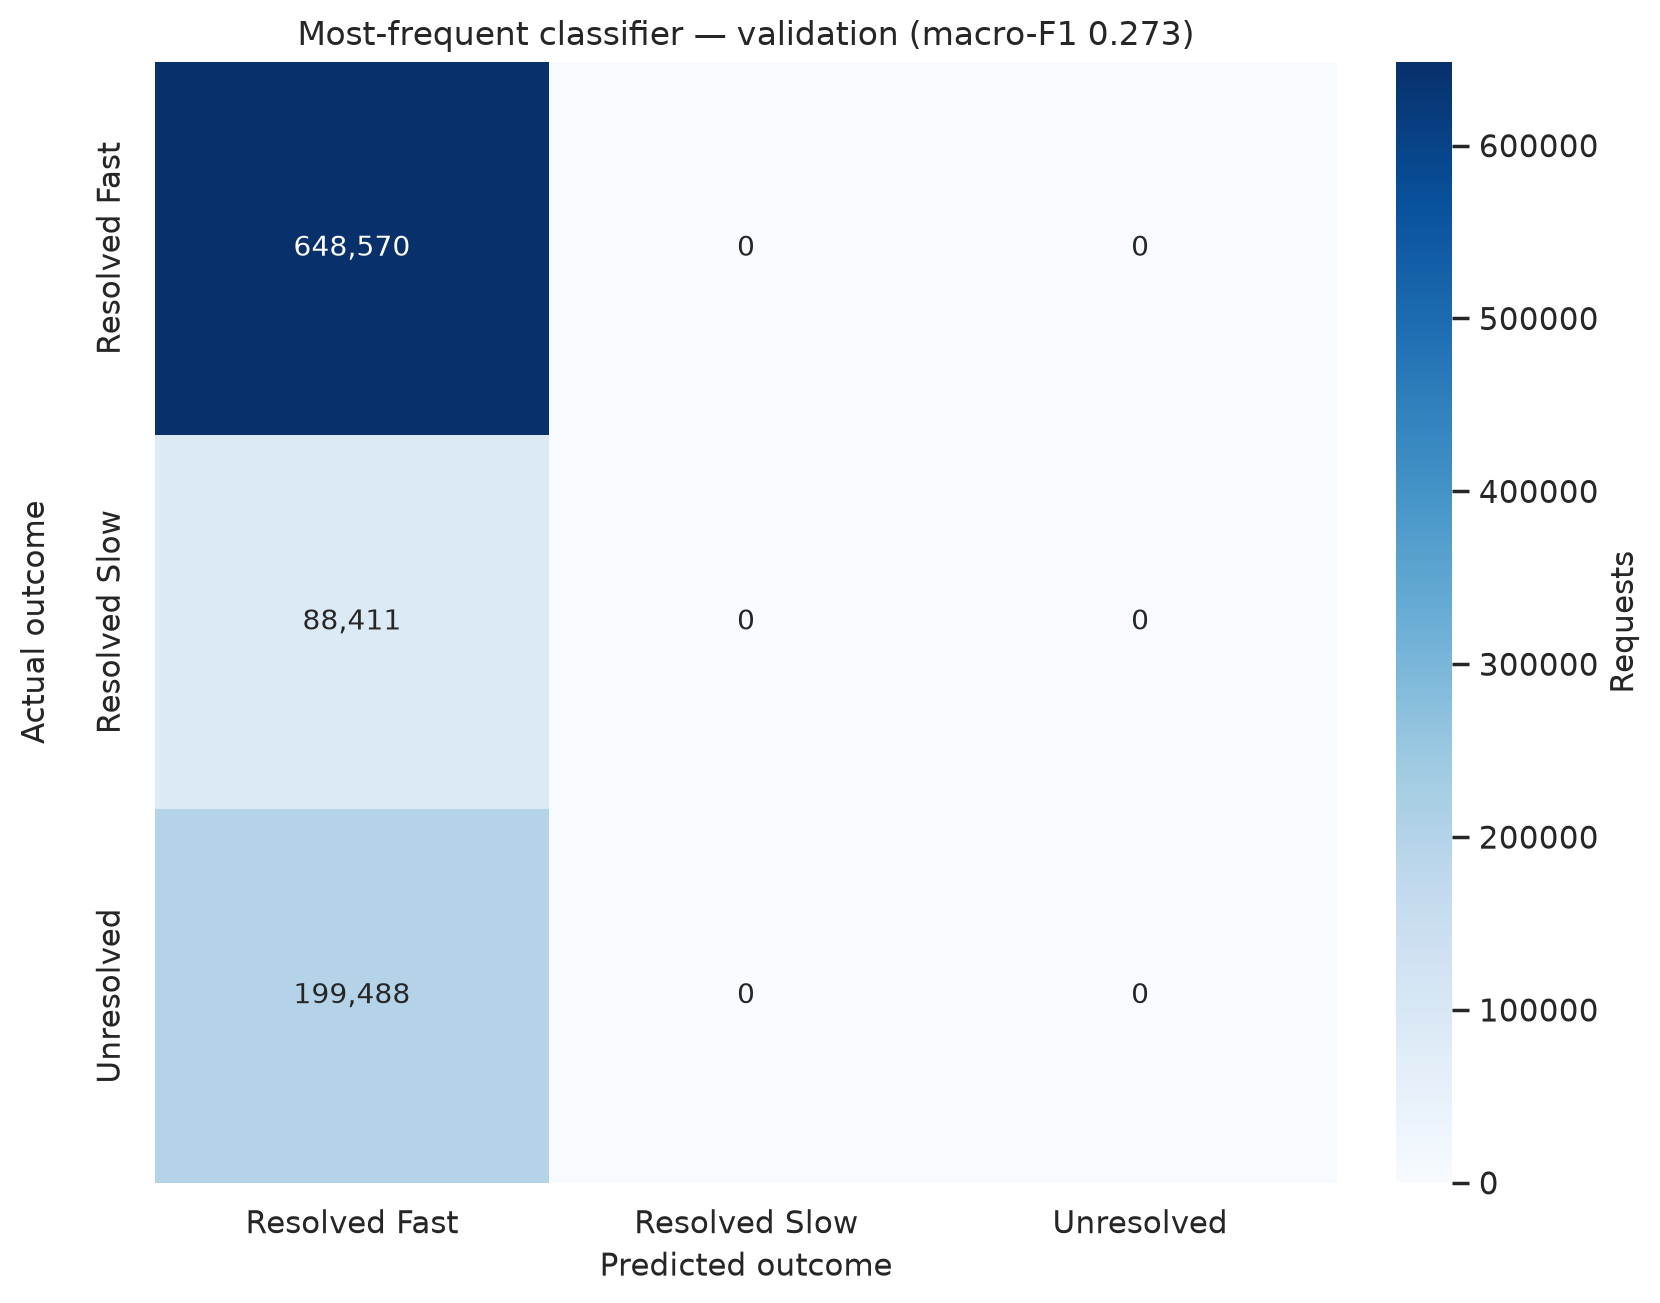

/workspace/results/figures/04_confusion_dummy_most_frequent_test.png


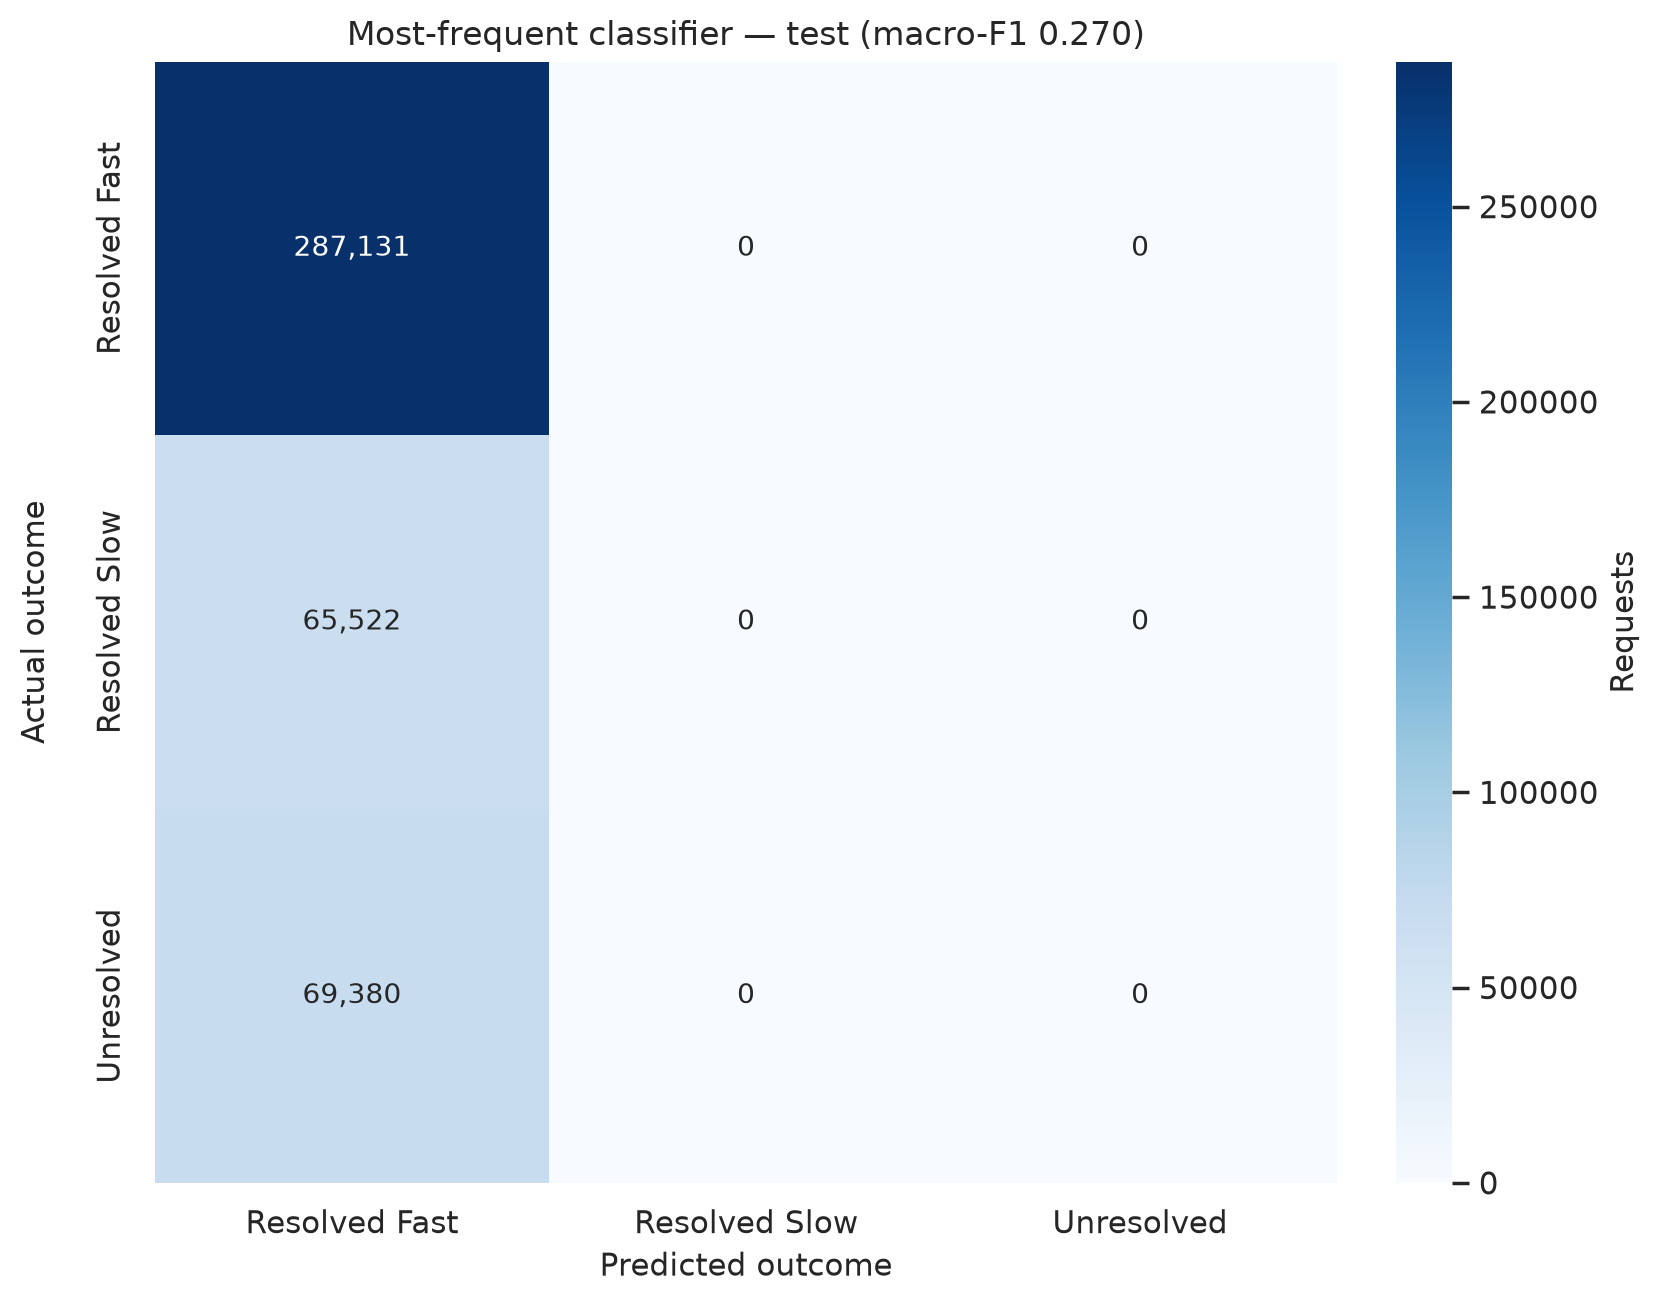

Most-frequent classifier validation probabilities: shape 936,469 x 3, classes ['Resolved Fast', 'Resolved Slow', 'Unresolved'], row sums 1.000000 to 1.000000


Logistic regression fit in 244.6 seconds; n_iter=[200]
The max_iter was reached which means the coef_ did not converge


/workspace/results/figures/04_confusion_logistic_regression_train.png


/workspace/results/figures/04_confusion_logistic_regression_validation.png


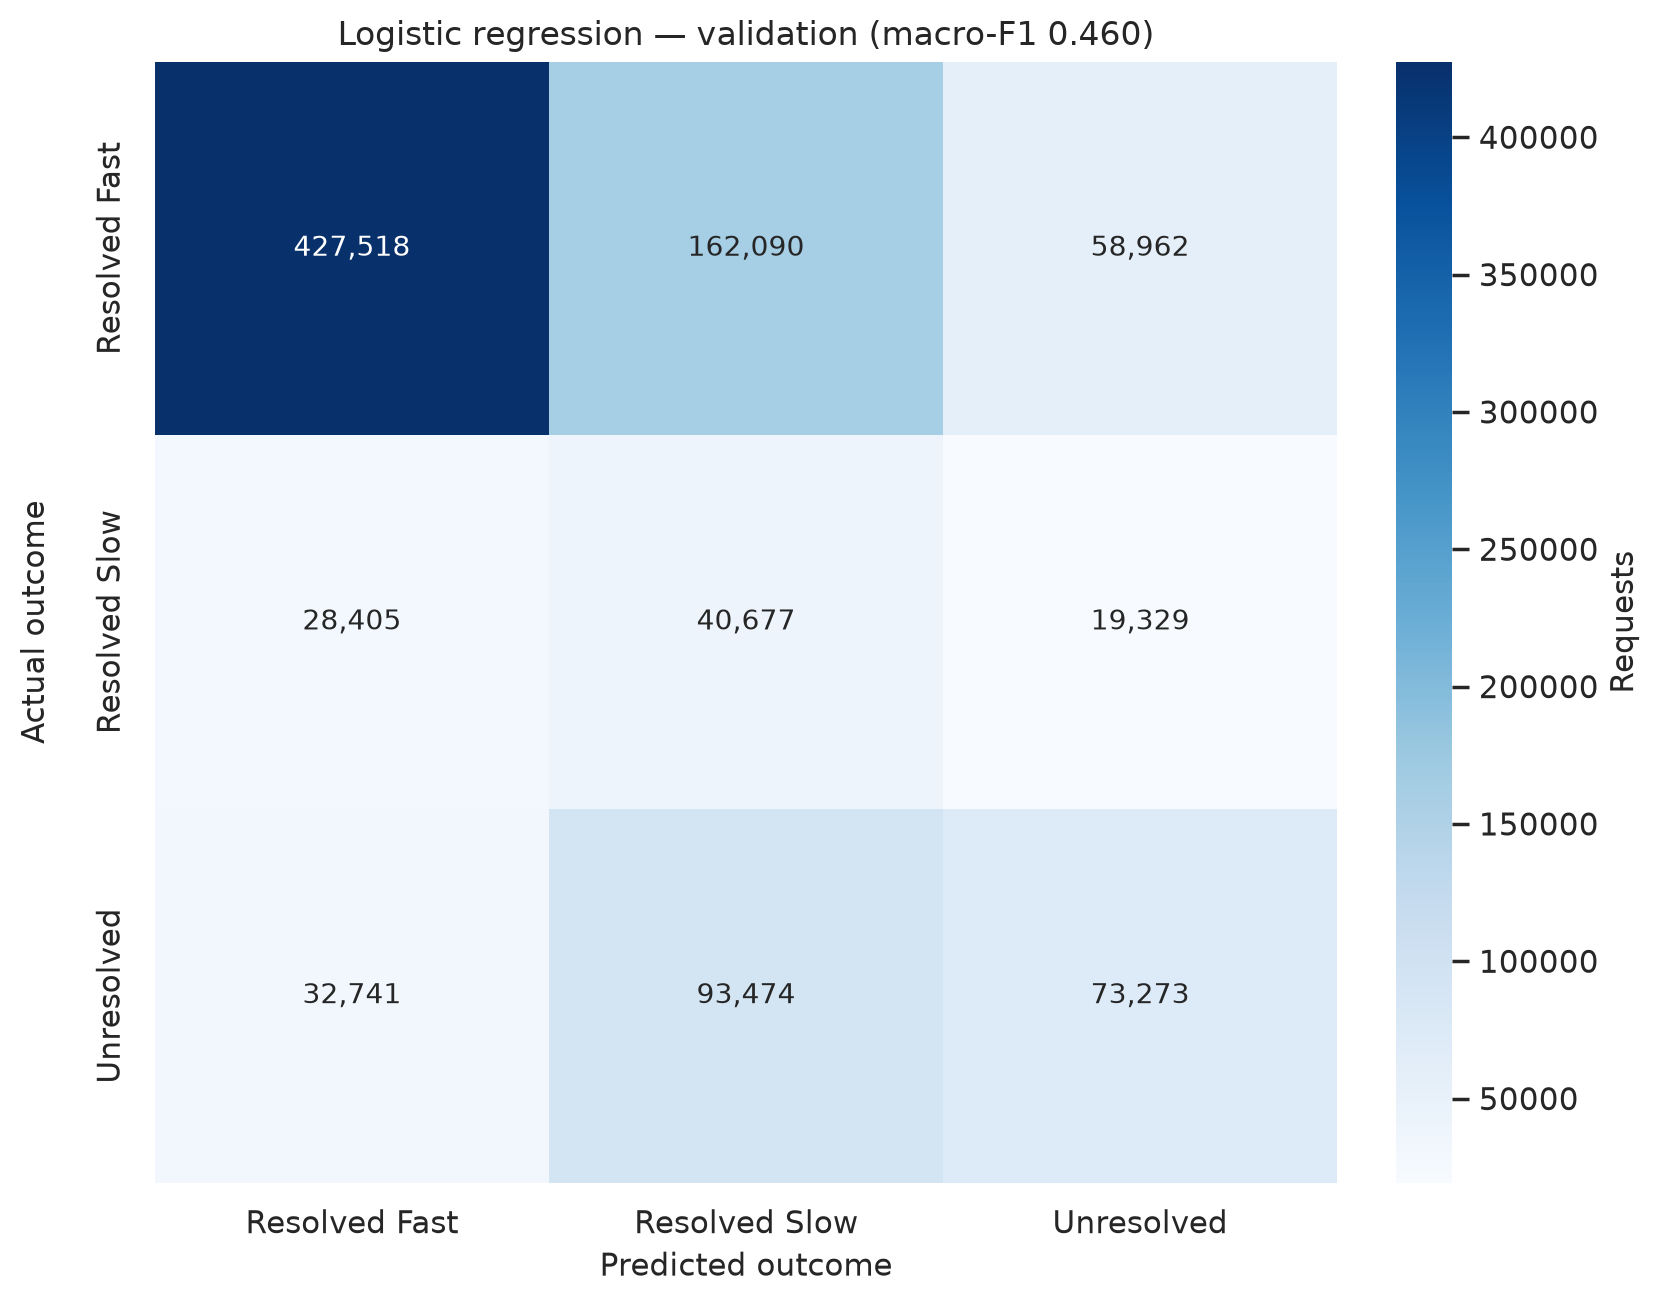

/workspace/results/figures/04_confusion_logistic_regression_test.png


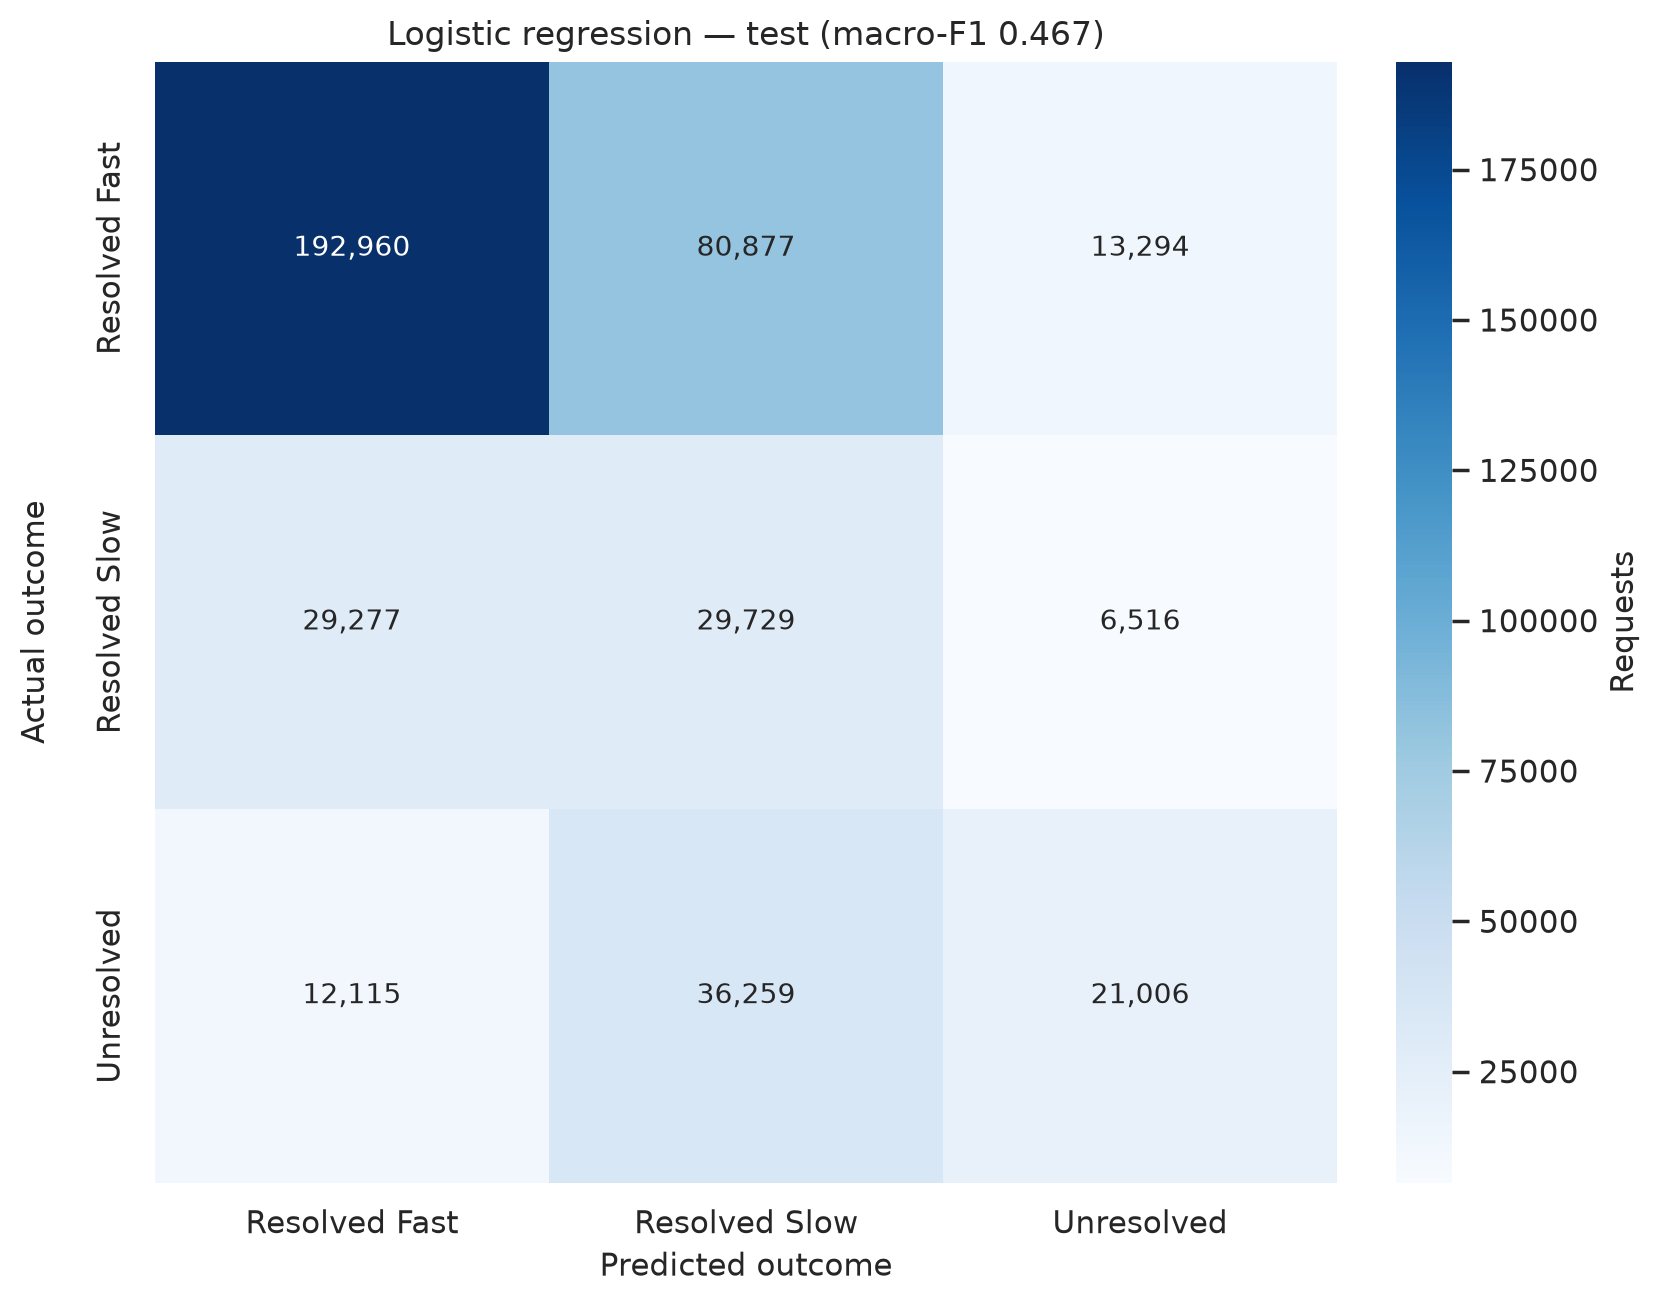

Logistic regression validation probabilities: shape 936,469 x 3, classes ['Resolved Fast', 'Resolved Slow', 'Unresolved'], row sums 1.000000 to 1.000000
/workspace/results/tables/04_baseline_summary.csv
/workspace/results/tables/04_baseline_per_class.csv
/workspace/results/tables/04_model_fit.csv


,model,fit_seconds,n_iter,convergence_warning
0,dummy_most_frequent,1.1,NaN,False
1,logistic_regression,244.6,200.0,True


,model,split,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved
0,dummy_most_frequent,train,0.6615,0.2654,0.5268,1.0000,0.0000,0.0000
1,dummy_most_frequent,validation,0.6926,0.2728,0.5668,1.0000,0.0000,0.0000
2,dummy_most_frequent,test,0.6804,0.2699,0.5509,1.0000,0.0000,0.0000
3,logistic_regression,train,0.6939,0.5782,0.7125,0.7534,0.5549,0.7244
4,logistic_regression,validation,0.5782,0.4603,0.6296,0.6592,0.4601,0.3673
5,logistic_regression,test,0.5774,0.4671,0.6096,0.6720,0.4537,0.3028


,model,split,label,precision,recall,f1,support
0,dummy_most_frequent,train,Resolved Fast,0.6615,1.0000,0.7963,1730948
1,dummy_most_frequent,train,Resolved Slow,0.0000,0.0000,0.0000,767337
2,dummy_most_frequent,train,Unresolved,0.0000,0.0000,0.0000,118310
3,dummy_most_frequent,validation,Resolved Fast,0.6926,1.0000,0.8184,648570
4,dummy_most_frequent,validation,Resolved Slow,0.0000,0.0000,0.0000,88411
5,dummy_most_frequent,validation,Unresolved,0.0000,0.0000,0.0000,199488
6,dummy_most_frequent,test,Resolved Fast,0.6804,1.0000,0.8098,287131
7,dummy_most_frequent,test,Resolved Slow,0.0000,0.0000,0.0000,65522
8,dummy_most_frequent,test,Unresolved,0.0000,0.0000,0.0000,69380
9,logistic_regression,train,Resolved Fast,0.8700,0.7534,0.8075,1730948


Balanced class weights from the training counts:
  Resolved Fast: 0.504
  Resolved Slow: 1.137
  Unresolved: 7.372


In [5]:
models = {
    "dummy_most_frequent": make_most_frequent_baseline(),
    "logistic_regression": make_logistic_baseline(),
}
display_names = {
    "dummy_most_frequent": "Most-frequent classifier",
    "logistic_regression": "Logistic regression",
}
matrices = {
    "train": X_train,
    "validation": X_validation,
    "test": X_test,
}
fit_rows = []
summary_frames = []
class_frames = []
for model_name, model in models.items():
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, targets["train"])
    elapsed = time.perf_counter() - started
    convergence_warnings = [str(item.message) for item in caught if issubclass(item.category, ConvergenceWarning)]
    n_iter = getattr(model, "n_iter_", None)
    fit_rows.append(
        {
            "model": model_name,
            "fit_seconds": round(elapsed, 1),
            "n_iter": None if n_iter is None else int(max(n_iter)),
            "convergence_warning": bool(convergence_warnings),
        }
    )
    print(f"{display_names[model_name]} fit in {elapsed:.1f} seconds; n_iter={n_iter}")
    for message in convergence_warnings:
        print(message)
    for split_name in ("train", "validation", "test"):
        predicted = model.predict(matrices[split_name])
        scores = classification_scores(targets[split_name], predicted, config.TARGET_LABELS)
        summary, per_class = metrics_tables(scores, model_name, split_name)
        summary_frames.append(summary)
        class_frames.append(per_class)
        figure_name = f"04_confusion_{model_name}_{split_name}.png"
        _figure, figure_path = plot_confusion_matrix(
            scores["confusion_matrix"],
            scores["labels"],
            f"{display_names[model_name]} — {split_name} (macro-F1 {scores['macro_f1']:.3f})",
            figure_name,
        )
        print(figure_path)
        if split_name != "train":
            display(Image(filename=str(figure_path)))
    probability = probability_summary(model, X_validation, config.TARGET_LABELS)
    print(
        f"{display_names[model_name]} validation probabilities: "
        f"shape {probability['rows']:,} x {probability['columns']}, "
        f"classes {probability['classes']}, "
        f"row sums {probability['row_sum_min']:.6f} to {probability['row_sum_max']:.6f}"
    )

summary_table = pd.concat(summary_frames, ignore_index=True)
per_class_table = pd.concat(class_frames, ignore_index=True)
metric_paths = save_metric_tables(summary_table, per_class_table, config.TABLES_DIR)
fit_table = pd.DataFrame(fit_rows)
fit_path = config.TABLES_DIR / "04_model_fit.csv"
fit_table.to_csv(fit_path, index=False)
print(metric_paths["summary"])
print(metric_paths["per_class"])
print(fit_path)
display(fit_table)
display(summary_table.round(4))
display(per_class_table.round(4))

class_counts = targets["train"].value_counts()
train_n = int(class_counts.sum())
print("Balanced class weights from the training counts:")
for label in config.TARGET_LABELS:
    weight = train_n / (len(config.TARGET_LABELS) * int(class_counts[label]))
    print(f"  {label}: {weight:.3f}")


## 6. Baseline results

The most-frequent classifier predicts Resolved Fast for every row. On the locked test its accuracy is 0.680 and its macro-F1 is 0.270. Recall is 1 for Resolved Fast and 0 for Resolved Slow and Unresolved. Accuracy here is the fast-class share, which is why macro-F1 is the primary score.

Logistic regression lowers accuracy to 0.577 on the locked test and raises macro-F1 to 0.467. Validation shows the same pattern: accuracy 0.578 and macro-F1 0.460, against the dummy macro-F1 of 0.273. On the locked test, Resolved Slow recall is 0.454 with precision 0.202, and Unresolved recall is 0.303 with precision 0.515. The balanced weights buy minority recall by predicting Slow and Unresolved more often than they occur. That is the intended baseline trade, not a tuned threshold.

Both models expose `predict_proba`. On the validation matrix the class columns are Resolved Fast, Resolved Slow, and Unresolved, and the probability rows sum to 1.

Logistic macro-F1 on the training rows is 0.578, compared with 0.460 on validation. The difference sits next to a real change in the class mix: Unresolved is 4.5% of training rows and 21.3% of validation rows. This notebook does not change the model because of that gap.

The solver reached 200 iterations without meeting the tolerance. The coefficients are the result of that run. `C` was not increased or decreased in response.


## 7. Limitations

- Work Center may be useful later if an assignment time shows it is known at logging. It is excluded here.
- Suburb still has 1,080 kept training levels, plus `(rare)` and `(missing)`. Placeholders such as `#` remain as their own levels when they are common in training.
- The validation year is not a copy of the training years. Unresolved rises from 4.5% in training to 21.3% in validation. A chronological split is supposed to expose that shift.
- Requests created after 30 April 2026 are not in the test score. A later model that is asked to score very recent open requests needs a separate rule for immature labels.
- The logistic fit did not converge under the pre-set iteration cap. This notebook does not search `C`, the rare-count threshold, or the class weights.
- No validation or test rows were resampled.


In [6]:
def _metric(model, split, column):
    row = summary_table.loc[(summary_table["model"] == model) & (summary_table["split"] == split)].iloc[0]
    return float(row[column])

def _class_metric(model, split, label, column):
    row = per_class_table.loc[
        (per_class_table["model"] == model)
        & (per_class_table["split"] == split)
        & (per_class_table["label"] == label)
    ].iloc[0]
    return float(row[column])

rare_bits = []
for _, rare_row in rare_summary.iterrows():
    rare_bits.append(
        f"- {rare_row['column']}: {int(rare_row['kept_categories']):,} of "
        f"{int(rare_row['distinct_categories']):,} training categories kept "
        f"({rare_row['kept_row_percent']:.1f}% of non-missing training rows)."
    )
lines = [
    "# Phase 4 baselines",
    "",
    "Notebook 03 fits two baselines on the labelled file. No champion was tuned.",
    "",
    "## Split",
    "",
    f"Random seed for the logistic solver: {config.RANDOM_SEED}. The split itself is chronological and does not use the seed.",
    "",
    f"- Train: {split_summary.loc[split_summary['split']=='train','start_date'].iloc[0]} to "
    f"{split_summary.loc[split_summary['split']=='train','end_date'].iloc[0]}, "
    f"{int(split_summary.loc[split_summary['split']=='train','rows'].iloc[0]):,} labelled requests.",
    f"- Validation: {split_summary.loc[split_summary['split']=='validation','start_date'].iloc[0]} to "
    f"{split_summary.loc[split_summary['split']=='validation','end_date'].iloc[0]}, "
    f"{int(split_summary.loc[split_summary['split']=='validation','rows'].iloc[0]):,} labelled requests. "
    "The validation window starts on 1 January 2025. January 2025 has no rows.",
    f"- Locked test: {split_summary.loc[split_summary['split']=='test','start_date'].iloc[0]} to "
    f"{split_summary.loc[split_summary['split']=='test','end_date'].iloc[0]}, "
    f"{int(split_summary.loc[split_summary['split']=='test','rows'].iloc[0]):,} labelled requests.",
    f"- Unlabelled rows excluded: {int(exclusions.loc[exclusions['reason']=='unlabelled_or_missing_created_date','rows'].iloc[0]):,}.",
    f"- Labelled rows created after {MATURE_END.date()} excluded: "
    f"{int(exclusions.loc[exclusions['reason']=='labelled_after_mature_end','rows'].iloc[0]):,}.",
    "",
    "Training class shares are 66.2% Resolved Fast, 29.3% Resolved Slow, and 4.5% Unresolved. "
    "Validation shares are 69.3% Resolved Fast, 9.4% Resolved Slow, and 21.3% Unresolved. "
    "Locked-test shares are 68.0% Resolved Fast, 15.5% Resolved Slow, and 16.4% Unresolved.",
    "",
    "The mature end is 30 April 2026 because May 2026 is where the labelled mix breaks: "
    "Unresolved rises sharply and Resolved Slow shrinks, with the extract ending on 6 October 2026. "
    "The cut was set from that monthly pattern before the models were fit. It was not chosen to maximise a score.",
    "",
    "## Predictors",
    "",
    "Included: complaint type, suburb, ward, subcouncil, weekday, month, and a weekend indicator. "
    "Weekday and month are one-hot encoded. The weekend indicator is standardised with a scaler fit on the training rows.",
    "",
    "Excluded: Work Center, because the extract has no assignment time; Created On Date as a raw timestamp; "
    "Completed Date; Changed on; resolution duration; the target; identifiers; and coordinates.",
    "",
    f"A training category is kept when it has at least {RARE_CATEGORY_MIN_COUNT} training rows. "
    "Rarer categories and categories first seen later become `(rare)`. Missing categorical values become `(missing)`.",
    "",
    *rare_bits,
    "",
    f"The encoded training matrix has {X_train.shape[1]:,} columns.",
    "",
    "## Scores",
    "",
    "Macro-F1 is the primary metric. The most-frequent dummy predicts the majority training class.",
    "",
    f"- Dummy validation: accuracy {_metric('dummy_most_frequent','validation','accuracy'):.3f}, "
    f"macro-F1 {_metric('dummy_most_frequent','validation','macro_f1'):.3f}, "
    f"weighted-F1 {_metric('dummy_most_frequent','validation','weighted_f1'):.3f}.",
    f"- Dummy locked test: accuracy {_metric('dummy_most_frequent','test','accuracy'):.3f}, "
    f"macro-F1 {_metric('dummy_most_frequent','test','macro_f1'):.3f}, "
    f"weighted-F1 {_metric('dummy_most_frequent','test','weighted_f1'):.3f}.",
    f"- Logistic validation: accuracy {_metric('logistic_regression','validation','accuracy'):.3f}, "
    f"macro-F1 {_metric('logistic_regression','validation','macro_f1'):.3f}, "
    f"weighted-F1 {_metric('logistic_regression','validation','weighted_f1'):.3f}.",
    f"- Logistic locked test: accuracy {_metric('logistic_regression','test','accuracy'):.3f}, "
    f"macro-F1 {_metric('logistic_regression','test','macro_f1'):.3f}, "
    f"weighted-F1 {_metric('logistic_regression','test','weighted_f1'):.3f}.",
    "",
    "Locked-test logistic precision and recall:",
    "",
    f"- Resolved Fast: precision {_class_metric('logistic_regression','test','Resolved Fast','precision'):.3f}, "
    f"recall {_class_metric('logistic_regression','test','Resolved Fast','recall'):.3f}.",
    f"- Resolved Slow: precision {_class_metric('logistic_regression','test','Resolved Slow','precision'):.3f}, "
    f"recall {_class_metric('logistic_regression','test','Resolved Slow','recall'):.3f}.",
    f"- Unresolved: precision {_class_metric('logistic_regression','test','Unresolved','precision'):.3f}, "
    f"recall {_class_metric('logistic_regression','test','Unresolved','recall'):.3f}.",
    "",
    "Training macro-F1 was "
    f"{_metric('dummy_most_frequent','train','macro_f1'):.3f} for the dummy and "
    f"{_metric('logistic_regression','train','macro_f1'):.3f} for logistic regression. "
    "The logistic training score is higher than the validation score. "
    "Validation and test were not resampled.",
    "",
    "## Limitations",
    "",
    "- The logistic solver stopped at the pre-set iteration cap before the tolerance was met.",
    "- `C`, the rare-count rule, and the class weights were not searched.",
    "- Balanced weights raise recall for Resolved Slow and Unresolved and lower precision for Resolved Slow.",
    "- Work Center remains unused until its assignment time is known.",
    "- The 2025 validation mix is substantially different from the 2023–2024 training mix.",
    "",
]
report_path = config.REPORTS_DIR / "phase4_baselines.md"
report_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(report_path)


/workspace/reports/phase4_baselines.md
